In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

import os

DATA_PATH = Path("../data/raw/winequality-white.csv")
OUTPUT_DIR = "../output/01_EDA"
os.makedirs(OUTPUT_DIR, exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (15,8)
plt.rcParams["axes.titlesize"] = 15

def save_fig(filename):
    file_path = os.path.join(OUTPUT_DIR, filename)
    plt.savefig(file_path, dpi=150, bbox_inches="tight")
    print(f"Graphique enregistré dans: {file_path}")


print("Imports effectués avec succès !")

Imports effectués avec succès !


In [2]:
df = pd.read_csv(DATA_PATH, sep=";")

print("=" * 75)
print(f"Notre jeu de données contient : {df.shape[0]} lignes et {df.shape[1]} colonnes")
print("=" * 75)
print("\n")

# Types et valeurs manquantes
inspection = pd.DataFrame({
    "dtype": df.dtypes,
    "nb_manquant": df.isnull().sum(),
    "pct_manquant": (df.isnull().sum()/len(df)*100).round(2),
    "nb_unique": df.nunique(),
    "example": df.iloc[0],
})


print(inspection)
print("\n")
print("=" * 75)
print("\n")

# Apercu de quelques données
df.head()

Notre jeu de données contient : 4898 lignes et 12 colonnes


                        dtype  nb_manquant  pct_manquant  nb_unique  example
fixed acidity         float64            0           0.0         68    7.000
volatile acidity      float64            0           0.0        125    0.270
citric acid           float64            0           0.0         87    0.360
residual sugar        float64            0           0.0        310   20.700
chlorides             float64            0           0.0        160    0.045
free sulfur dioxide   float64            0           0.0        132   45.000
total sulfur dioxide  float64            0           0.0        251  170.000
density               float64            0           0.0        890    1.001
pH                    float64            0           0.0        103    3.000
sulphates             float64            0           0.0         79    0.450
alcohol               float64            0           0.0        103    8.800
quality        

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


### Analyse univariée

Graphique enregistré dans: ../output/01_EDA/eda_analyse_univariee.png


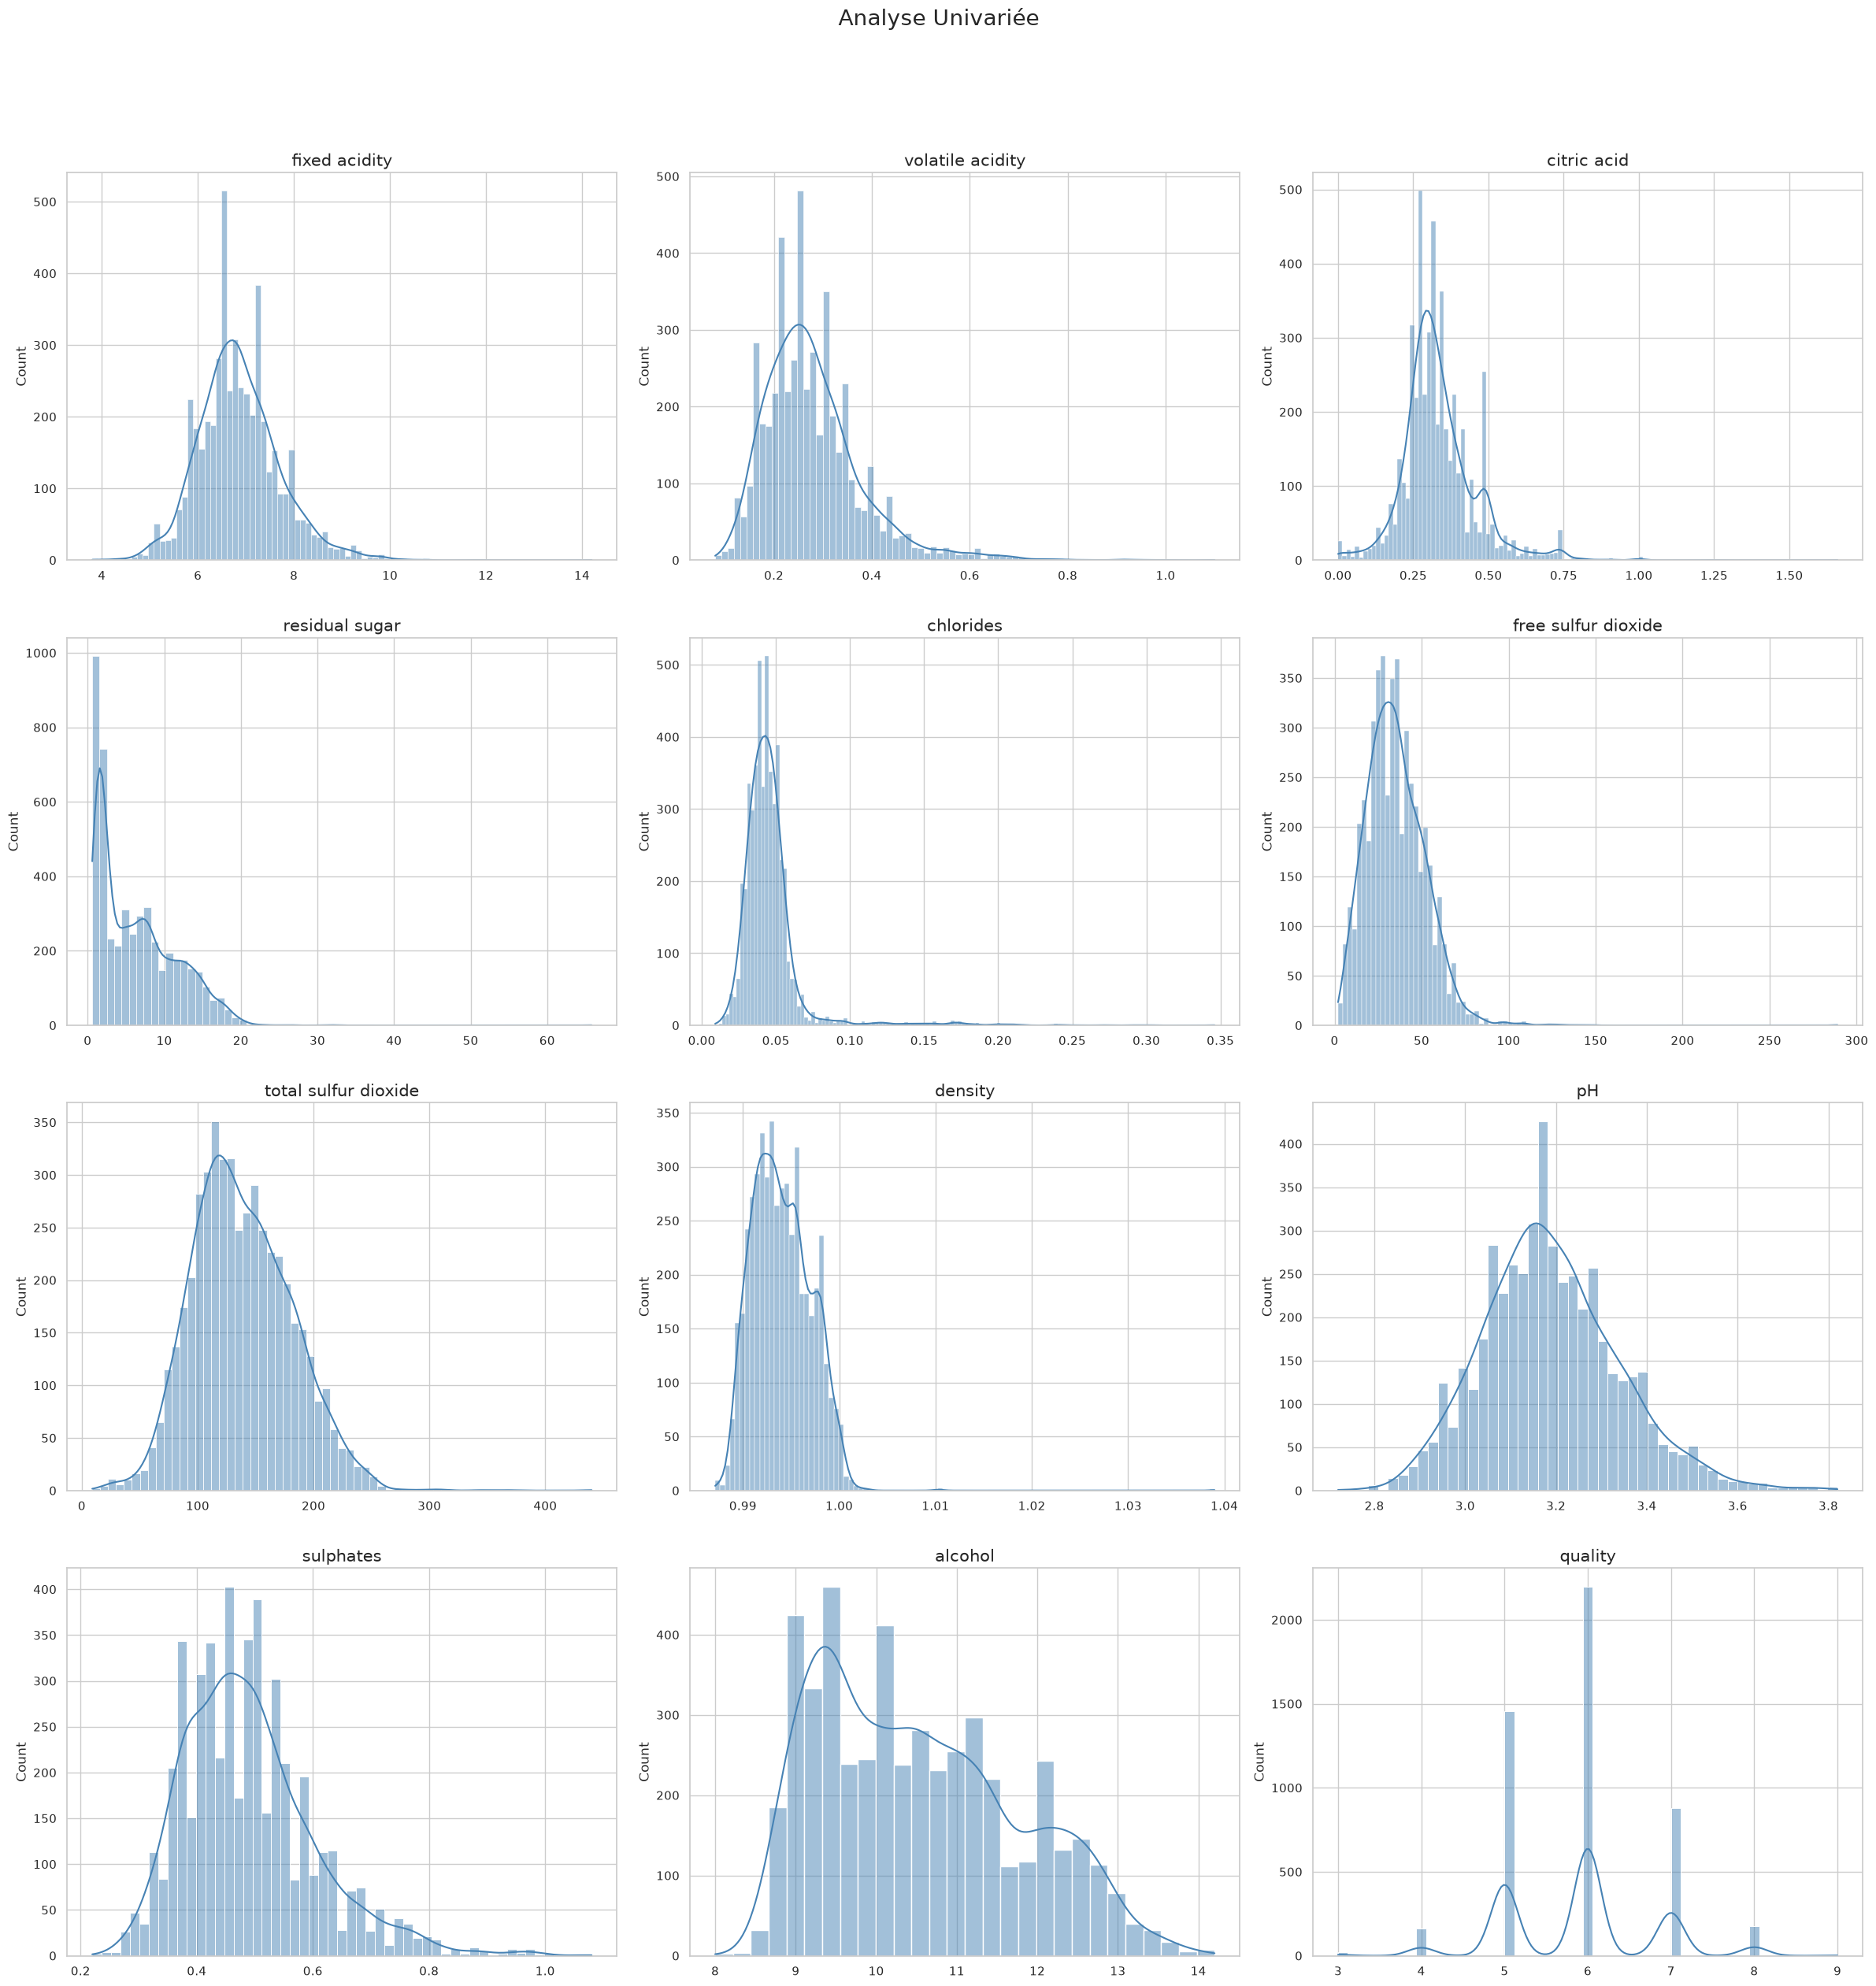

In [3]:
# --- 2. Distributions univariées - Numériques
def plot_distributions(pathname, cols, titre, n_cols=3):
    """
    Affiche les histogrammes + KDE pour une liste de colonnes.
    ncols : nombre de colonnes par ligne.
    """
    n_figures = len(cols)
    n_rows = math.ceil(n_figures / n_cols)
    figure, all_axes = plt.subplots(nrows = n_rows, ncols=n_cols, figsize=(8 * n_cols, 6 * n_rows))
    figure.suptitle(titre, fontsize=20, y=1.05)
    axes_flat = all_axes.flatten()
    for axe, column in zip(axes_flat, cols):
        sns.histplot(df[column], kde=True, ax=axe, color="steelblue")
        axe.set_title(column)
        axe.set_xlabel("")


    for axe in axes_flat[n_figures:]:
        axe.set_visible(False)

    plt.tight_layout()
    plt.subplots_adjust(hspace=0.2)
    save_fig(pathname)
    plt.show()


plot_distributions("eda_analyse_univariee.png", df.columns, "Analyse Univariée")


### Détection des outliers

Graphique enregistré dans: ../output/01_EDA/eda_outliers_boxplots.png


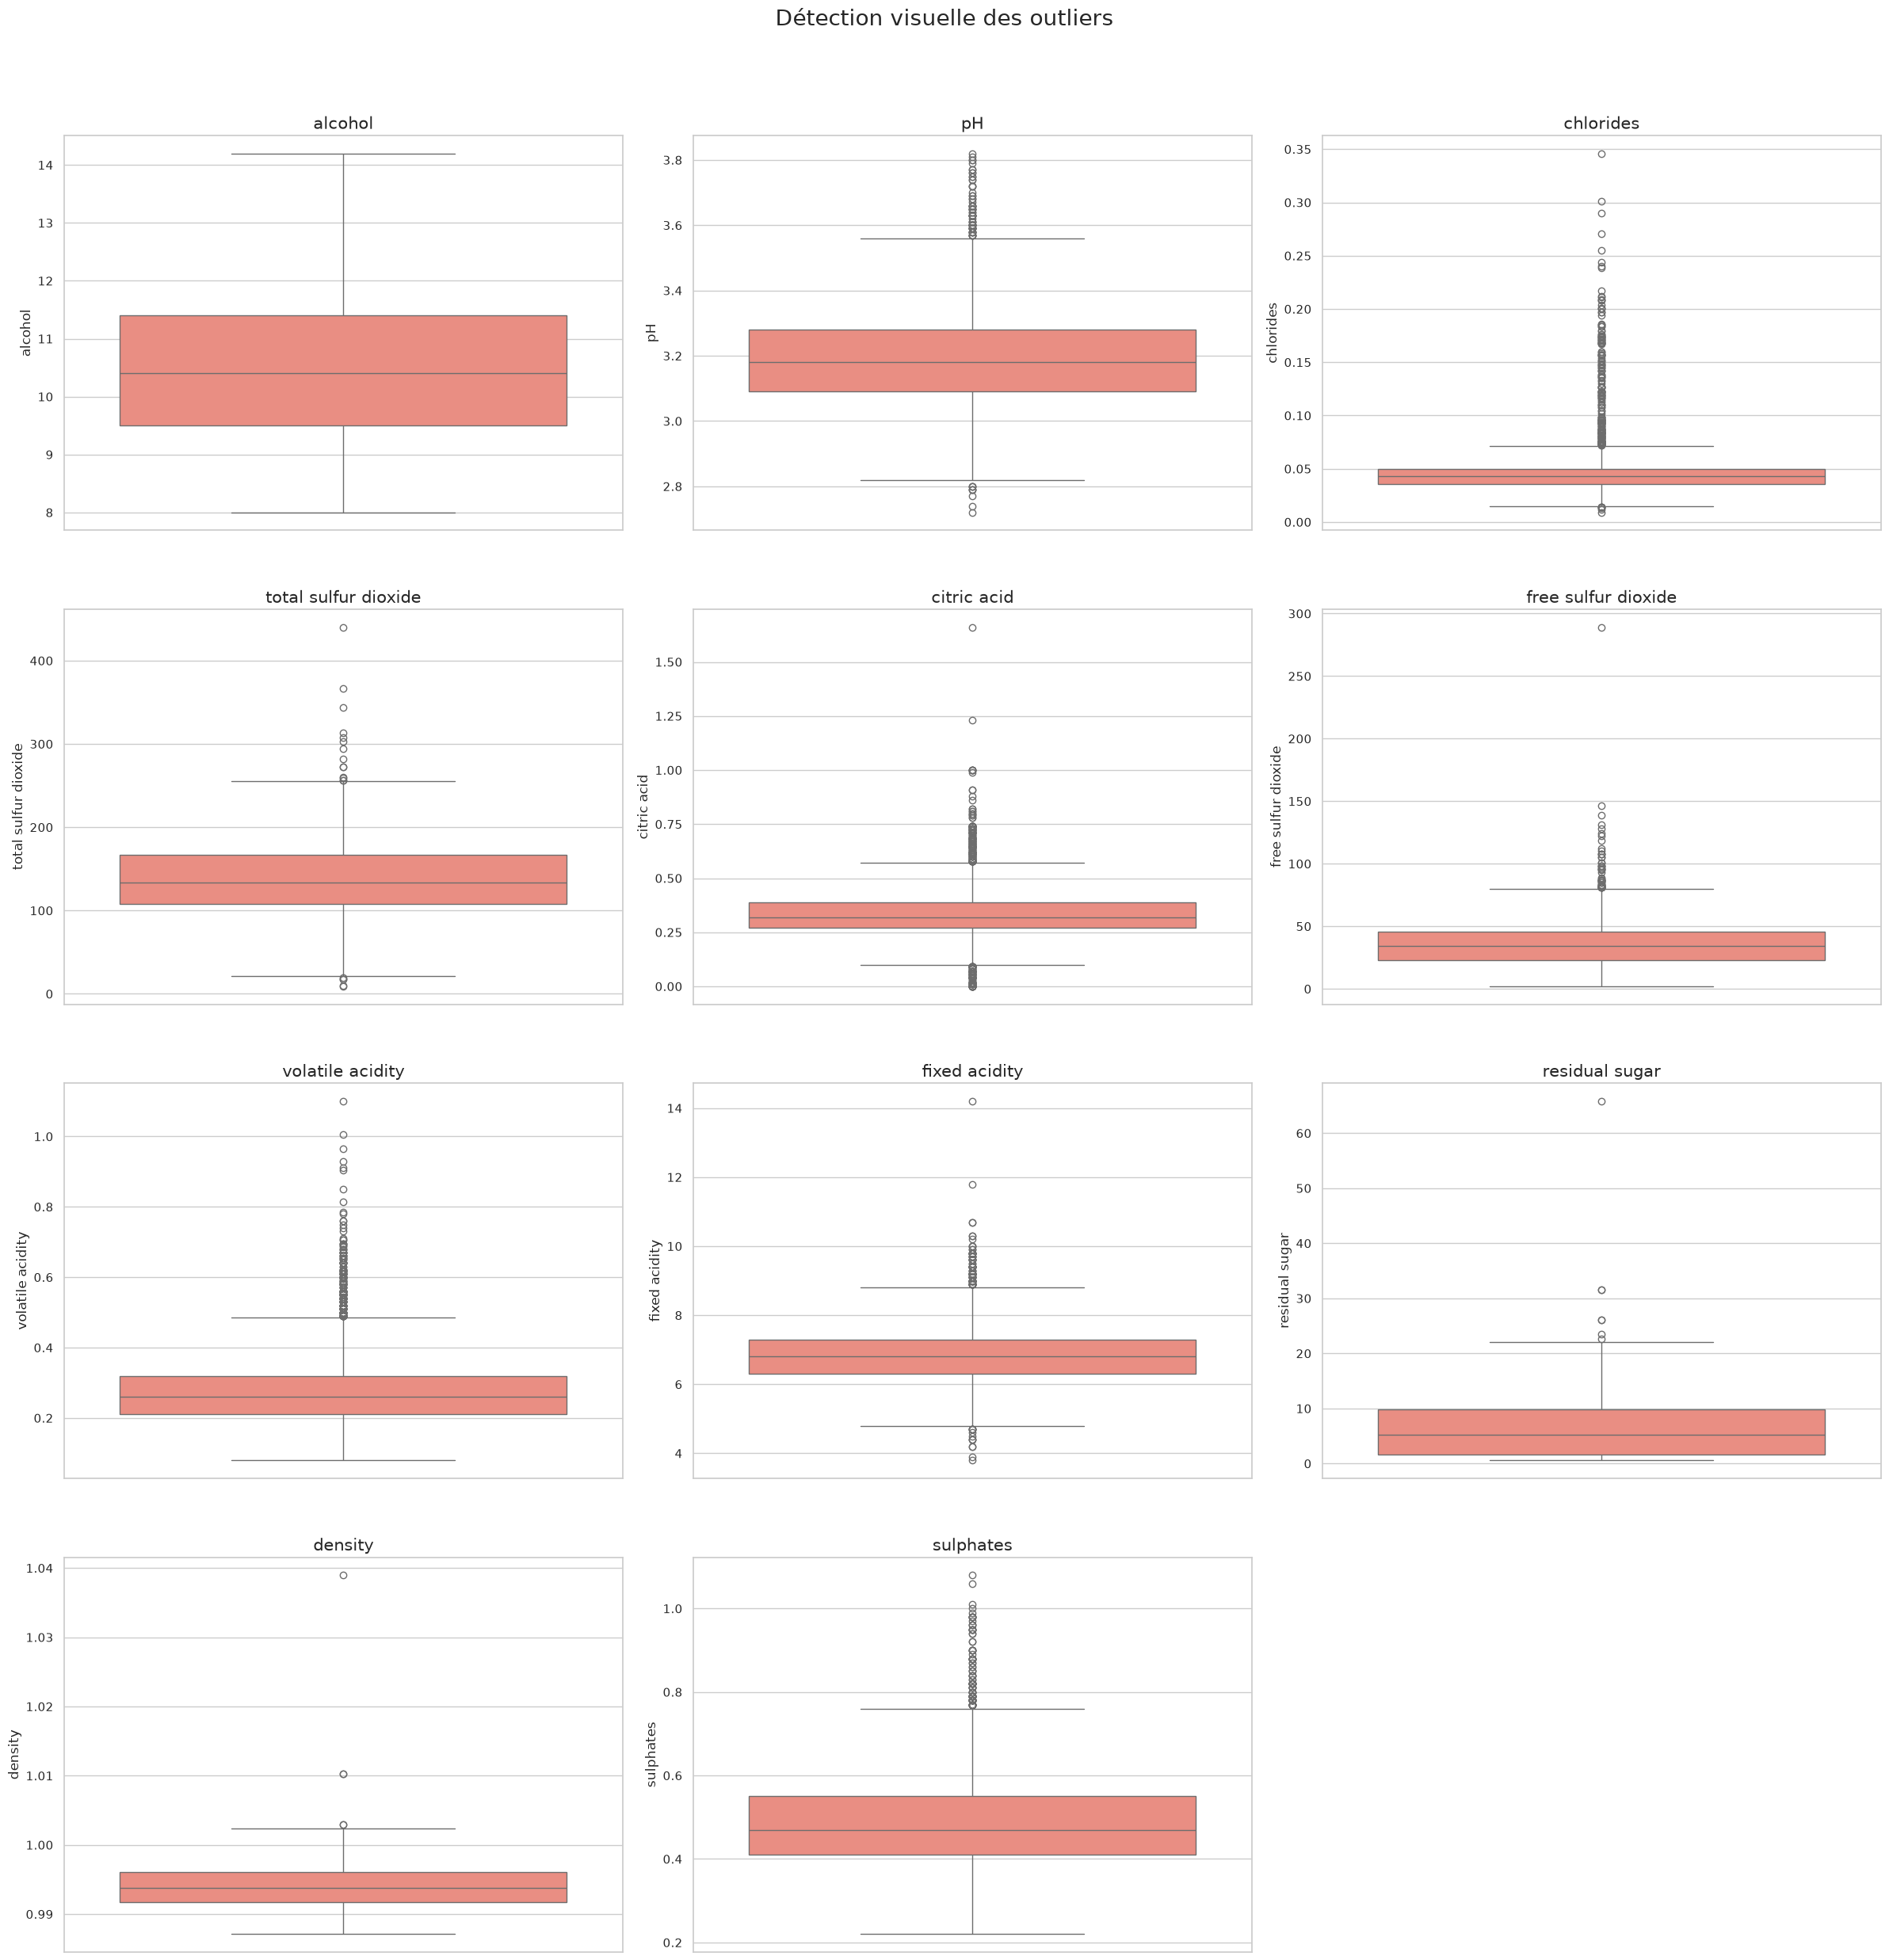


--- Outliers détectés (méthode IQR) ---
pH                             ->   75 outliers
chlorides                      ->  208 outliers
total sulfur dioxide           ->   19 outliers
citric acid                    ->  270 outliers
free sulfur dioxide            ->   50 outliers
volatile acidity               ->  186 outliers
fixed acidity                  ->  119 outliers
residual sugar                 ->    7 outliers
density                        ->    5 outliers
sulphates                      ->  124 outliers


In [4]:
# --- 4. Détection des outliers  - BOXPLOTS
features = frozenset(df.columns).difference({"quality"})
n_cols = 3
n_rows = math.ceil(len(features) / n_cols)

fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(n_cols * 8,  n_rows * 6))
fig.suptitle("Détection visuelle des outliers", fontsize=20, y=1.03)
axes_flat = axes.flatten()

for ax, col in zip(axes_flat, features):
    sns.boxplot(y=df[col], ax=ax, color="salmon")
    ax.set_title(col)


for axe in axes_flat[len(features):]:
        axe.set_visible(False)

plt.tight_layout()
plt.subplots_adjust(hspace=0.2)
save_fig("eda_outliers_boxplots.png")
plt.show()


# Quantifier les outliers avec la méthode IQR
print("\n--- Outliers détectés (méthode IQR) ---")
for col in features:
    Q1 = df[col].quantile(0.25)
    Q3  = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = df[(df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)]
    if len(outliers) > 0 :
        print(f"{col:30s} -> {len(outliers):4d} outliers")



### Matrice de corrélation

Graphique enregistré dans: ../output/01_EDA/eda_correlation_heatmap.png


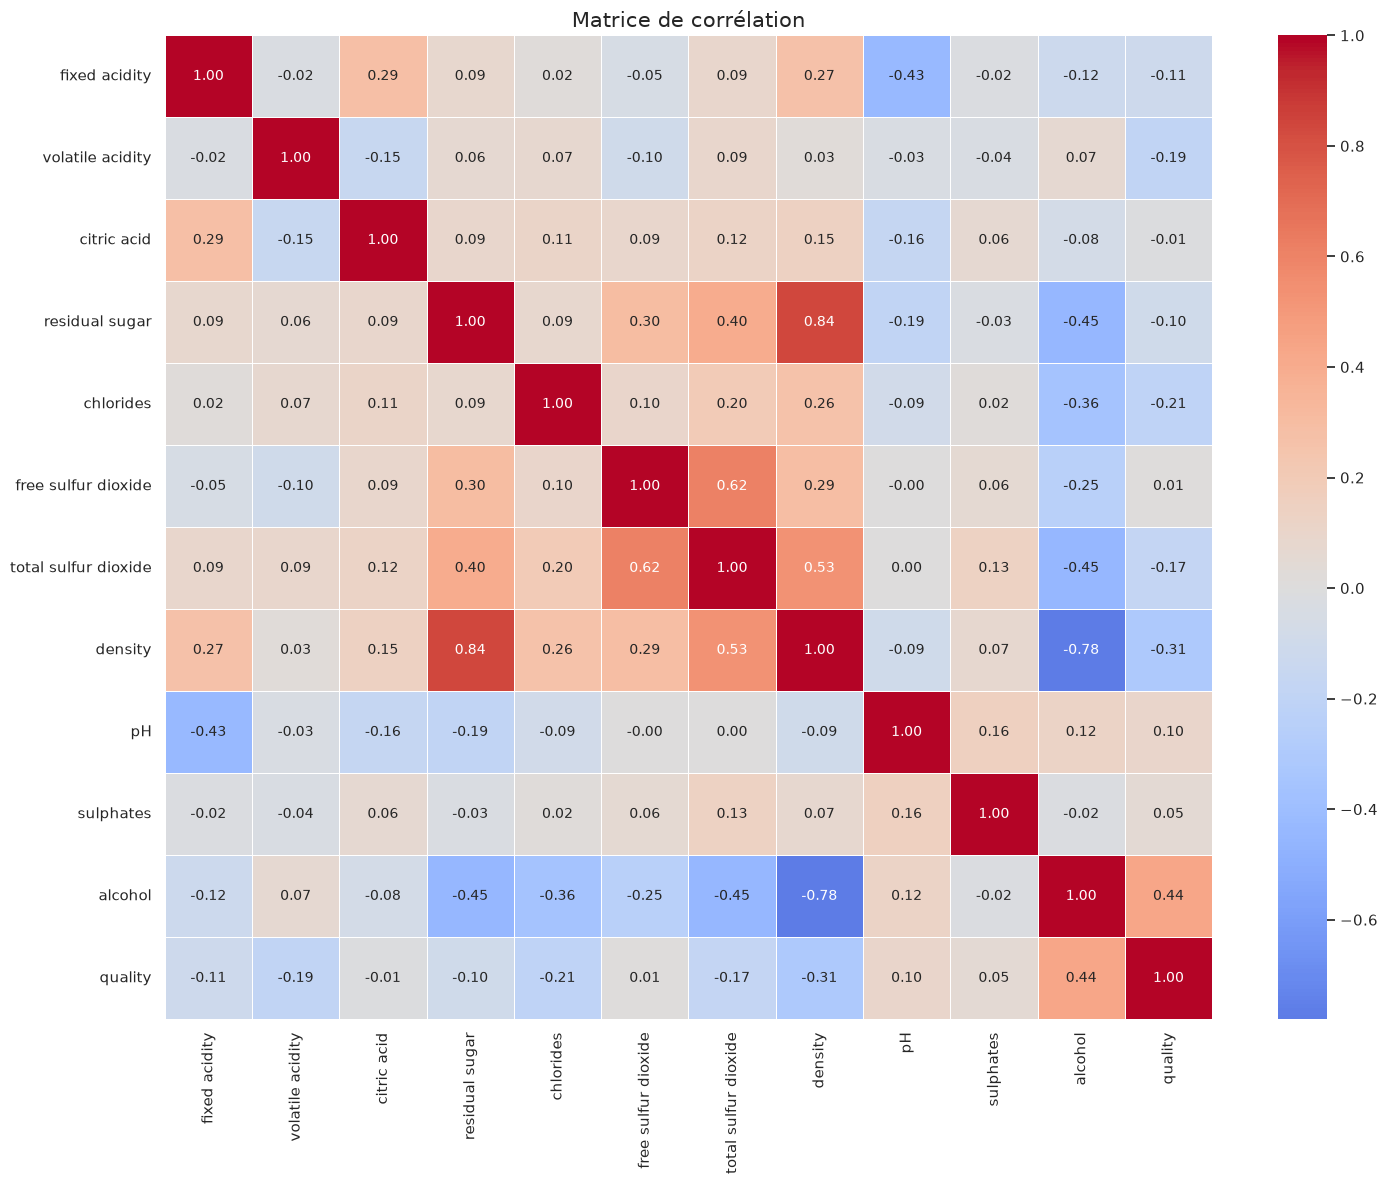

In [5]:
# --- 5. Matrice de corrélation ---

# On sélectionne uniquement les colonnes numériques pertinentes
corr_matrix = df[df.columns].corr()

plt.figure(figsize=(15, 12))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=.5,
    annot_kws={"size": 10},
)
plt.title("Matrice de corrélation")
plt.tight_layout()
save_fig("eda_correlation_heatmap.png")
plt.show()


### Synthèse EDA — Décisions pour le Preprocessing

1. **Valeurs manquantes**
Notre dataset ne possède pas de valeurs manquantes.

2. **Gestion des outliers**

La méthode utilisée pour détecter les outliers est l'IQR (Inter-Quartile). Nous avons au vu des résultats tiré les conclusions suivantes:


| Variable | Valeurs aberrantes détectées | Décision |
|---|---|---|
| **pH** | Valeurs inférieures à 3, anormalement faibles et très peu représentées. | Supprimer les observations concernées. |
| **citric acid** | 270 valeurs détectées. | Remplacer par la médiane. |
| **chlorides** | 208 valeurs détectées. | Remplacer par la médiane. |
| **volatile acidity** | 186 valeurs détectées. | Remplacer par la médiane. |
| **sulphates** | 124 valeurs détectées. | Remplacer par la médiane. |
| **fixed acidity** | 119 valeurs détectées. | Remplacer par la médiane. |
| **free sulfur dioxide** | 50 valeurs détectées. | Remplacer par la médiane. |
| **residual sugar** | 7 valeurs détectées. | Supprimer les 7 observations concernées. |
| **density** | 5 valeurs détectées. | Supprimer les 5 observations concernées. |


3. **Variables à supprimer**

La variable quantitative quality sera à supprimer pour faire notre clustering. Elle nous servira plutard


4. **Observation Analytiques**

- La variable ``residual sugar`` est fortement corrélée à ``density`` $r=0.84$. Un vin moins sucré est dense. Elles pourraient être un levier pour discriminer les clusters.
- Les variables ``residual sugar`` et ``alcohol`` sont moyennement corrélées en sens inverse $r=-0.45$; ce qui est cohérent car lors de la fermentation alcoolique, le sucre est transformé en alcool.
- Les variables ``density`` et ``alcohol`` sont fortement corrélés en sens inverse $r=-0.78$. On pourrait donc observer dans les clusters finaux pour des vins de qualité supérieure un taux d'alcool peu moyennement eĺevé mais une densité assez faible.
- Les variables ``total sulfur dioxide`` et ``free sulfur dioxide`` sont moyennement corrélées $r=0.62$. Cela peut s'expliquer par le fait que ces variables donnent pratiquement les memes informations.
- Les variables ``total sulfur dioxide`` et ``density`` sont elles aussi moyennement corrélées $r=0.53$.
- Les variables ``total sulfur dioxide`` et ``alcohol`` sont moyennement corrélées en sens inverse $r=-0.45$. On comprend donc que dans ce dataset, les vins les plus alcoolisés ont tendance à présenter moins de $SO_{2}$ total.
